In [3]:
!nvidia-smi

Fri Nov 13 16:10:53 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 581.95                 Driver Version: 581.95         CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                  Driver-Model | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce RTX 3050 ...  WDDM  |   00000000:01:00.0 Off |                  N/A |
| N/A   40C    P8              4W /   90W |     339MiB /   4096MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [3]:
import torch
import torchvision
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)
print("NumPy version:", np.__version__)

print("CUDA available:", torch.cuda.is_available())

PyTorch version: 2.15.0+cpu
Torchvision version: 0.29.2+cpu
NumPy version: 2.5.4
CUDA available: False


In [1]:
import torch
import torchvision

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Selected device:", device)
print("GPU:", torch.cuda.get_device_name(0))

# Create tensors directly on the GPU
a = torch.randn(2000, 2000, device=device)
b = torch.randn(2000, 2000, device=device)

# Perform matrix multiplication
c = torch.matmul(a, b)

print("Result shape:", c.shape)
print("Result device:", c.device)
print("GPU memory allocated:", round(torch.cuda.memory_allocated() / 1024**2, 2), "MB")

Selected device: cuda
GPU: NVIDIA GeForce RTX 3050 Laptop GPU
Result shape: torch.Size([2000, 2000])
Result device: cuda:0
GPU memory allocated: 56.12 MB


In [5]:
from pathlib import Path
import pyarrow.parquet as pq

dataset_path = Path("../dataset/brain_tumor_dataset")

parquet_files = sorted(dataset_path.glob("*.parquet"))

print("Parquet files found:", len(parquet_files))

for file in parquet_files:
    parquet_file = pq.ParquetFile(file)

    print(f"\nFile: {file.name}")
    print("Rows:", parquet_file.metadata.num_rows)
    print("Columns:", parquet_file.schema.names)

Parquet files found: 4

File: test-00000-of-00001.parquet
Rows: 542
Columns: ['id', 'pid', 'label_id', 'label_name', 'fold', 'bytes', 'path', 'bytes', 'path', 'element']

File: train-00000-of-00003.parquet
Rows: 841
Columns: ['id', 'pid', 'label_id', 'label_name', 'fold', 'bytes', 'path', 'bytes', 'path', 'element']

File: train-00001-of-00003.parquet
Rows: 841
Columns: ['id', 'pid', 'label_id', 'label_name', 'fold', 'bytes', 'path', 'bytes', 'path', 'element']

File: train-00002-of-00003.parquet
Rows: 840
Columns: ['id', 'pid', 'label_id', 'label_name', 'fold', 'bytes', 'path', 'bytes', 'path', 'element']


In [11]:
import pandas as pd

print("Pandas version:", pd.__version__)

metadata_tables = []

for file in parquet_files:
    table = pq.read_table(
        file,
        columns=["id", "pid", "label_id", "label_name", "fold"]
    )

    metadata_tables.append(table.to_pandas())

metadata = pd.concat(metadata_tables, ignore_index=True)

print("Total records:", len(metadata))
print("Unique patients:", metadata["pid"].nunique())

print("\nClass distribution:")
print(metadata["label_name"].value_counts())

print("\nOriginal fold distribution:")
print(metadata["fold"].value_counts().sort_index())

print("\nFirst 5 records:")
display(metadata.head())

Pandas version: 3.1.1
Total records: 3064
Unique patients: 233

Class distribution:
label_name
glioma        1426
pituitary      930
meningioma     708
Name: count, dtype: int64

Original fold distribution:
fold
1    542
2    679
3    572
4    628
5    643
Name: count, dtype: int64

First 5 records:


,id,pid,label_id,label_name,fold
0,24,102420,1,meningioma,1
1,25,102420,1,meningioma,1
2,27,102675,1,meningioma,1
3,34,102935,1,meningioma,1
4,60,105937,1,meningioma,1


In [17]:
# Create patient-level metadata
patient_metadata = (
    metadata.groupby("pid")
    .agg(
        label_id=("label_id", "nunique"),
        label_name=("label_name", "first"),
        fold=("fold", "first"),
        fold_count=("fold", "nunique"),
        image_count=("id", "count")
    )
    .reset_index()
)

# Verify patient metadata
print("Total patients:", len(patient_metadata))

print(
    "Patients with multiple classes:",
    (patient_metadata["label_id"] != 1).sum()
)

print(
    "Patients appearing in multiple folds:",
    (patient_metadata["fold_count"] != 1).sum()
)

print("\nPatients by original fold:")
print(patient_metadata["fold"].value_counts().sort_index())

# Separate original training and test patients
test_patients = patient_metadata[
    patient_metadata["fold"] == 1
].copy()

training_pool = patient_metadata[
    patient_metadata["fold"] != 1
].copy()

print("\nOriginal training patients:", len(training_pool))
print("Original test patients:", len(test_patients))

Total patients: 233
Patients with multiple classes: 0
Patients appearing in multiple folds: 0

Patients by original fold:
fold
1    45
2    46
3    48
4    47
5    47
Name: count, dtype: int64

Original training patients: 188
Original test patients: 45


In [19]:
from sklearn.model_selection import StratifiedShuffleSplit

# Split training patients into 80% training and 20% validation
splitter = StratifiedShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, val_idx = next(
    splitter.split(
        training_pool["pid"],
        training_pool["label_name"]
    )
)

train_patients = training_pool.iloc[train_idx].copy()
val_patients = training_pool.iloc[val_idx].copy()

# Get image-level records for each partition
train_data = metadata[
    metadata["pid"].isin(train_patients["pid"])
].copy()

val_data = metadata[
    metadata["pid"].isin(val_patients["pid"])
].copy()

test_data = metadata[
    metadata["fold"] == 1
].copy()

# Display split statistics
print("TRAINING")
print("Patients:", train_patients["pid"].nunique())
print("Images:", len(train_data))

print("\nVALIDATION")
print("Patients:", val_patients["pid"].nunique())
print("Images:", len(val_data))

print("\nTEST")
print("Patients:", test_patients["pid"].nunique())
print("Images:", len(test_data))

TRAINING
Patients: 150
Images: 1991

VALIDATION
Patients: 38
Images: 531

TEST
Patients: 45
Images: 542


In [21]:
# Check patient overlap
train_ids = set(train_patients["pid"])
val_ids = set(val_patients["pid"])
test_ids = set(test_patients["pid"])

print("Train-validation overlap:", len(train_ids & val_ids))
print("Train-test overlap:", len(train_ids & test_ids))
print("Validation-test overlap:", len(val_ids & test_ids))

# Check class distribution at patient level
print("\nPATIENT CLASS DISTRIBUTION")

for name, data in [
    ("Training", train_patients),
    ("Validation", val_patients),
    ("Test", test_patients)
]:
    print(f"\n{name}:")
    print(data["label_name"].value_counts().sort_index())

# Check image counts
print("\nIMAGE COUNTS")
print("Training:", len(train_data))
print("Validation:", len(val_data))
print("Test:", len(test_data))
print("Total:", len(train_data) + len(val_data) + len(test_data))

Train-validation overlap: 0
Train-test overlap: 0
Validation-test overlap: 0

PATIENT CLASS DISTRIBUTION

Training:
label_name
glioma        57
meningioma    53
pituitary     40
Name: count, dtype: int64

Validation:
label_name
glioma        15
meningioma    13
pituitary     10
Name: count, dtype: int64

Test:
label_name
glioma        17
meningioma    16
pituitary     12
Name: count, dtype: int64

IMAGE COUNTS
Training: 1991
Validation: 531
Test: 542
Total: 3064


In [23]:
# Create output directory for split files
split_dir = dataset_path / "splits"
split_dir.mkdir(parents=True, exist_ok=True)

# Add partition labels to image metadata
train_manifest = train_data.copy()
train_manifest["split"] = "train"

val_manifest = val_data.copy()
val_manifest["split"] = "validation"

test_manifest = test_data.copy()
test_manifest["split"] = "test"

# Combine all image records
split_manifest = pd.concat(
    [train_manifest, val_manifest, test_manifest],
    ignore_index=True
)

# Save image-level split information
split_manifest.to_csv(
    split_dir / "split_manifest.csv",
    index=False
)

# Save patient-level split information
patient_splits = pd.concat([
    train_patients.assign(split="train"),
    val_patients.assign(split="validation"),
    test_patients.assign(split="test")
], ignore_index=True)

patient_splits.to_csv(
    split_dir / "patient_splits.csv",
    index=False
)

print("Split files saved successfully!")
print("Location:", split_dir.resolve())

print("\nImage split counts:")
print(split_manifest["split"].value_counts())

print("\nTotal records:", len(split_manifest))

Split files saved successfully!
Location: C:\Users\vanga\OneDrive\Desktop\project me\BrainSight\dataset\brain_tumor_dataset\splits

Image split counts:
split
train         1991
test           542
validation     531
Name: count, dtype: int64

Total records: 3064


In [25]:
from PIL import Image
from io import BytesIO
import numpy as np

print("Pillow imported successfully")
print("NumPy version:", np.__version__)

Pillow imported successfully
NumPy version: 2.5.4


In [27]:
train_file = dataset_path / "train-00000-of-00003.parquet"

parquet_file = pq.ParquetFile(train_file)

print("Parquet schema:")
print(parquet_file.schema_arrow)

Parquet schema:
id: string
pid: string
label_id: int32
label_name: string
fold: int32
image: struct<bytes: binary, path: string>
  child 0, bytes: binary
  child 1, path: string
mask: struct<bytes: binary, path: string>
  child 0, bytes: binary
  child 1, path: string
tumor_border: list<element: double>
  child 0, element: double
-- schema metadata --
huggingface: '{"info": {"features": {"id": {"dtype": "string", "_type": "' + 348


In [29]:
table = pq.read_table(
    train_file,
    columns=["id", "pid", "label_name", "image"]
)

first_record = table.slice(0, 1).to_pylist()[0]

image_bytes = first_record["image"]["bytes"]

print("Image ID:", first_record["id"])
print("Patient ID:", first_record["pid"])
print("Tumor class:", first_record["label_name"])
print("Image bytes:", len(image_bytes))

Image ID: 1
Patient ID: 100360
Tumor class: meningioma
Image bytes: 215162


In [31]:
image = Image.open(BytesIO(image_bytes))

print("Image format:", image.format)
print("Image mode:", image.mode)
print("Image dimensions:", image.size)
print("Image data type:", np.array(image).dtype)

Image format: PNG
Image mode: I;16
Image dimensions: (512, 512)
Image data type: uint16


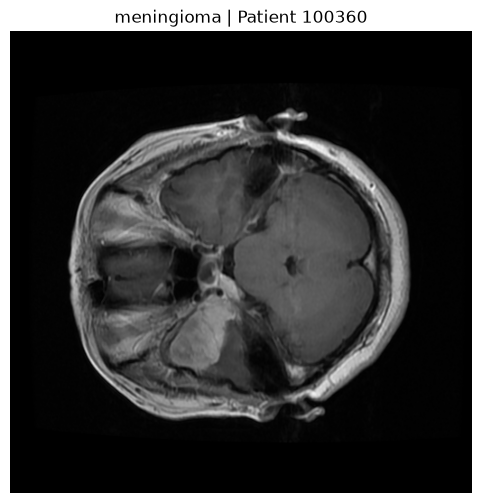

Minimum pixel value: 0
Maximum pixel value: 3366
Mean pixel value: 441.48
Standard deviation: 617.1


In [35]:
import matplotlib.pyplot as plt

image_array = np.array(image)

plt.figure(figsize=(6, 6))
plt.imshow(image_array, cmap="gray")
plt.title(f"{first_record['label_name']} | Patient {first_record['pid']}")
plt.axis("off")
plt.show()

print("Minimum pixel value:", image_array.min())
print("Maximum pixel value:", image_array.max())
print("Mean pixel value:", round(image_array.mean(), 2))
print("Standard deviation:", round(image_array.std(), 2))

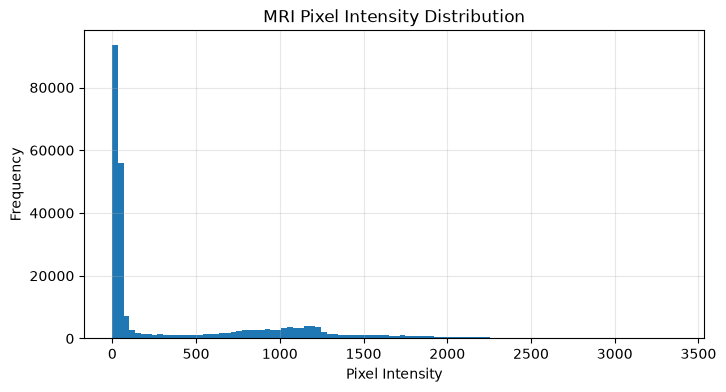

Intensity percentiles:
25%: 0.00
50%: 49.00
75%: 892.00
90%: 1318.00
95%: 1722.00
99%: 2325.00
99.9%: 2897.00


In [37]:
plt.figure(figsize=(8, 4))

plt.hist(image_array.ravel(), bins=100)

plt.title("MRI Pixel Intensity Distribution")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")
plt.grid(alpha=0.3)

plt.show()

print("Intensity percentiles:")
for p in [25, 50, 75, 90, 95, 99, 99.9]:
    print(f"{p}%: {np.percentile(image_array, p):.2f}")

In [39]:
total_pixels = image_array.size
zero_pixels = np.sum(image_array == 0)
nonzero_pixels = image_array[image_array > 0]

print("Total pixels:", total_pixels)
print("Zero-valued pixels:", zero_pixels)
print("Zero pixel percentage:", round((zero_pixels / total_pixels) * 100, 2), "%")

print("\nNon-zero pixel statistics:")
print("Minimum:", nonzero_pixels.min())
print("Maximum:", nonzero_pixels.max())
print("Median:", np.median(nonzero_pixels))
print("95th percentile:", np.percentile(nonzero_pixels, 95))
print("99th percentile:", np.percentile(nonzero_pixels, 99))

Total pixels: 262144
Zero-valued pixels: 70374
Zero pixel percentage: 26.85 %

Non-zero pixel statistics:
Minimum: 1
Maximum: 3366
Median: 301.0
95th percentile: 1852.0
99th percentile: 2438.0


In [41]:
import pyarrow as pa

sample_metadata = table.select(
    ["pid", "label_name"]
).to_pandas()

sample_patients = (
    sample_metadata
    .drop_duplicates("pid")
    .groupby("label_name", group_keys=False)
    .sample(n=2, random_state=42)
)

sample_results = []

for _, patient in sample_patients.iterrows():
    index = sample_metadata.index[
        sample_metadata["pid"] == patient["pid"]
    ][0]

    record = table.slice(index, 1).to_pylist()[0]
    img = np.array(
        Image.open(BytesIO(record["image"]["bytes"]))
    )

    sample_results.append({
        "Patient": patient["pid"],
        "Class": patient["label_name"],
        "Resolution": f"{img.shape[1]}x{img.shape[0]}",
        "Zero %": round(np.mean(img == 0) * 100, 2),
        "Median": round(np.median(img), 2),
        "95th percentile": round(np.percentile(img, 95), 2),
        "99th percentile": round(np.percentile(img, 99), 2),
        "Maximum": int(img.max())
    })

sample_stats = pd.DataFrame(sample_results)
sample_stats

,Patient,Class,Resolution,Zero %,Median,95th percentile,99th percentile,Maximum
0,100820,glioma,512x512,27.33,71.0,1562.0,2826.0,4284
1,101020,glioma,512x512,27.01,54.0,1139.0,1696.0,2404
2,108514,meningioma,512x512,27.51,58.0,1449.0,2724.0,3707
3,100360,meningioma,512x512,26.85,49.0,1722.0,2325.0,3366
4,106062,pituitary,512x512,8.21,199.0,469.0,629.0,879
5,58392,pituitary,512x512,1.50,203.0,462.0,648.0,906


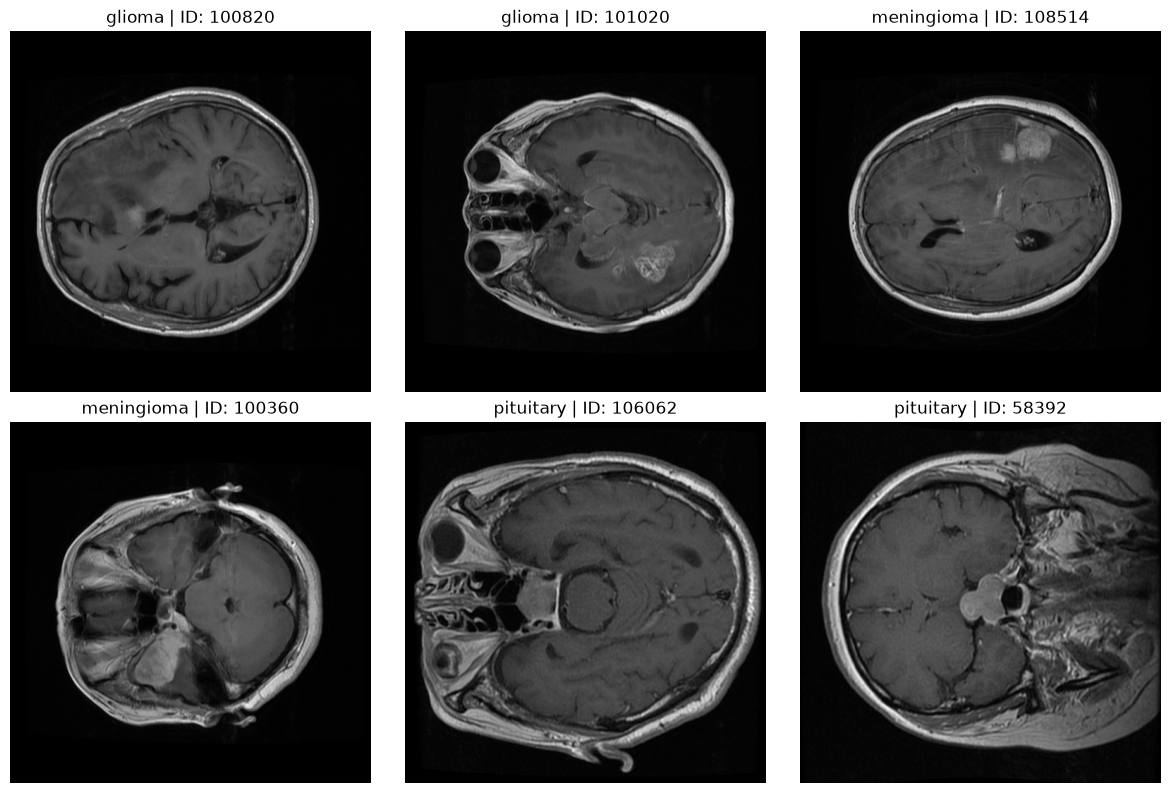

In [43]:
fig, axes = plt.subplots(2, 3, figsize=(12, 8))

for ax, (_, patient) in zip(axes.ravel(), sample_patients.iterrows()):
    patient_id = patient["pid"]

    index = sample_metadata.index[
        sample_metadata["pid"] == patient_id
    ][0]

    record = table.slice(index, 1).to_pylist()[0]

    img = np.array(
        Image.open(BytesIO(record["image"]["bytes"]))
    )

    ax.imshow(img, cmap="gray")
    ax.set_title(f"{patient['label_name']} | ID: {patient_id}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [45]:
split_dir = dataset_path / "splits"

split_manifest = pd.read_csv(
    split_dir / "split_manifest.csv"
)

patient_splits = pd.read_csv(
    split_dir / "patient_splits.csv"
)

print("IMAGE SPLITS")
print(split_manifest["split"].value_counts())

print("\nPATIENT SPLITS")
print(patient_splits["split"].value_counts())

print("\nCLASS DISTRIBUTION")
print(
    patient_splits.groupby(
        ["split", "label_name"]
    )["pid"].count()
)

print("\nTotal image records:", len(split_manifest))
print("Unique patients:", patient_splits["pid"].nunique())

IMAGE SPLITS
split
train         1991
test           542
validation     531
Name: count, dtype: int64

PATIENT SPLITS
split
train         150
test           45
validation     38
Name: count, dtype: int64

CLASS DISTRIBUTION
split       label_name
test        glioma        17
            meningioma    16
            pituitary     12
train       glioma        57
            meningioma    53
            pituitary     40
validation  glioma        15
            meningioma    13
            pituitary     10
Name: pid, dtype: int64

Total image records: 3064
Unique patients: 233


In [47]:
print("Manifest columns:")
print(split_manifest.columns.tolist())

print("\nFirst five records:")
display(split_manifest.head())

print("\nData types:")
print(split_manifest.dtypes)

Manifest columns:
['id', 'pid', 'label_id', 'label_name', 'fold', 'split']

First five records:


,id,pid,label_id,label_name,fold,split
0,6,100572,1,meningioma,3,train
1,7,100572,1,meningioma,3,train
2,8,100572,1,meningioma,3,train
3,9,101016,1,meningioma,4,train
4,10,101016,1,meningioma,4,train



Data types:
id            int64
pid             str
label_id      int64
label_name      str
fold          int64
split           str
dtype: object


In [49]:
parquet_ids = set()

for file in parquet_files:
    table_ids = pq.read_table(
        file,
        columns=["id"]
    ).column("id").to_pylist()

    parquet_ids.update(table_ids)

manifest_ids = set(split_manifest["id"].astype(str))

print("Unique Parquet image IDs:", len(parquet_ids))
print("Unique manifest image IDs:", len(manifest_ids))
print("IDs missing from Parquet:", len(manifest_ids - parquet_ids))
print("IDs missing from manifest:", len(parquet_ids - manifest_ids))

Unique Parquet image IDs: 3064
Unique manifest image IDs: 3064
IDs missing from Parquet: 0
IDs missing from manifest: 0


In [51]:
processed_dir = dataset_path.parent / "processed"

for split in ["train", "validation", "test"]:
    for class_name in ["glioma", "meningioma", "pituitary"]:
        folder = processed_dir / split / class_name
        folder.mkdir(parents=True, exist_ok=True)

print("Output directories created successfully!")
print("Location:", processed_dir.resolve())

Output directories created successfully!
Location: C:\Users\vanga\OneDrive\Desktop\project me\BrainSight\dataset\processed


In [55]:
manifest_lookup = split_manifest.set_index("id").to_dict("index")

extracted_count = 0

for file in parquet_files:
    table = pq.read_table(
        file,
        columns=["id", "image"]
    )

    records = table.to_pylist()

    for record in records:
        image_id = int(record["id"])
        image_info = manifest_lookup[image_id]

        split = image_info["split"]
        class_name = image_info["label_name"]

        output_folder = processed_dir / split / class_name
        output_path = output_folder / f"{image_id}.png"

        image_bytes = record["image"]["bytes"]

        with open(output_path, "wb") as image_file:
            image_file.write(image_bytes)

        extracted_count += 1

    print(f"Processed {file.name} | Total: {extracted_count}")

print("\nExtraction completed!")
print("Total images extracted:", extracted_count)

Processed test-00000-of-00001.parquet | Total: 542
Processed train-00000-of-00003.parquet | Total: 1383
Processed train-00001-of-00003.parquet | Total: 2224
Processed train-00002-of-00003.parquet | Total: 3064

Extraction completed!
Total images extracted: 3064


In [57]:
for split in ["train", "validation", "test"]:
    print(f"\n{split.upper()}")

    total = 0

    for class_name in ["glioma", "meningioma", "pituitary"]:
        folder = processed_dir / split / class_name

        count = len(list(folder.glob("*.png")))
        total += count

        print(f"{class_name}: {count}")

    print("Total:", total)


TRAIN
glioma: 958
meningioma: 443
pituitary: 590
Total: 1991

VALIDATION
glioma: 223
meningioma: 153
pituitary: 155
Total: 531

TEST
glioma: 245
meningioma: 112
pituitary: 185
Total: 542


In [59]:
from collections import Counter

image_modes = Counter()
image_sizes = Counter()
corrupted_images = []

for split in ["train", "validation", "test"]:
    for class_name in ["glioma", "meningioma", "pituitary"]:
        folder = processed_dir / split / class_name

        for image_path in folder.glob("*.png"):
            try:
                with Image.open(image_path) as img:
                    img.verify()

                with Image.open(image_path) as img:
                    image_modes[img.mode] += 1
                    image_sizes[img.size] += 1

            except Exception:
                corrupted_images.append(str(image_path))

print("Image modes:", image_modes)
print("\nImage dimensions:", image_sizes)
print("\nCorrupted images:", len(corrupted_images))

Image modes: Counter({'I;16': 3064})

Image dimensions: Counter({(512, 512): 3049, (256, 256): 15})

Corrupted images: 0


In [61]:
small_images = []

for split in ["train", "validation", "test"]:
    for class_name in ["glioma", "meningioma", "pituitary"]:
        folder = processed_dir / split / class_name

        for path in folder.glob("*.png"):
            with Image.open(path) as img:
                if img.size == (256, 256):
                    small_images.append(path)

print("Number of 256x256 images:", len(small_images))
print("Example paths:")

for path in small_images[:5]:
    print(path)

Number of 256x256 images: 15
Example paths:
..\dataset\processed\train\pituitary\1070.png
..\dataset\processed\train\pituitary\1071.png
..\dataset\processed\train\pituitary\1072.png
..\dataset\processed\train\pituitary\1073.png
..\dataset\processed\train\pituitary\1074.png


In [65]:
sample_512 = None

for folder in (processed_dir / "train").iterdir():
    for path in folder.glob("*.png"):
        with Image.open(path) as img:
            if img.size == (512, 512):
                sample_512 = path
                break
    if sample_512 is not None:
        break

sample_256 = small_images[0]

for path in [sample_512, sample_256]:
    with Image.open(path) as img:
        print(f"File: {path.name}")
        print(f"Original size: {img.size}")
        print(f"Original mode: {img.mode}")

        resized = img.resize((224, 224), Image.Resampling.BILINEAR)

        print(f"Resized size: {resized.size}")
        print(f"Resized mode: {resized.mode}")
        print("-" * 40)

File: 1853.png
Original size: (512, 512)
Original mode: I;16
Resized size: (224, 224)
Resized mode: I;16
----------------------------------------
File: 1070.png
Original size: (256, 256)
Original mode: I;16
Resized size: (224, 224)
Resized mode: I;16
----------------------------------------


In [67]:
for path in [sample_512, sample_256]:
    with Image.open(path) as img:
        resized = img.resize((224, 224), Image.Resampling.BILINEAR)
        pixels = np.array(resized, dtype=np.float32)

        print(f"File: {path.name}")
        print(f"Minimum: {pixels.min():.2f}")
        print(f"Maximum: {pixels.max():.2f}")
        print(f"Mean: {pixels.mean():.2f}")
        print(f"Standard deviation: {pixels.std():.2f}")
        print("-" * 40)

File: 1853.png
Minimum: 0.00
Maximum: 5817.00
Mean: 739.17
Standard deviation: 907.20
----------------------------------------
File: 1070.png
Minimum: 0.00
Maximum: 250.00
Mean: 55.05
Standard deviation: 39.69
----------------------------------------


In [69]:
for path in [sample_512, sample_256]:
    with Image.open(path) as img:
        resized = img.resize((224, 224), Image.Resampling.BILINEAR)
        pixels = np.array(resized, dtype=np.float32)

        p1 = np.percentile(pixels, 1)
        p50 = np.percentile(pixels, 50)
        p99 = np.percentile(pixels, 99)

        print(f"File: {path.name}")
        print(f"1st percentile: {p1:.2f}")
        print(f"Median: {p50:.2f}")
        print(f"99th percentile: {p99:.2f}")
        print("-" * 40)

File: 1853.png
1st percentile: 0.00
Median: 92.00
99th percentile: 3547.25
----------------------------------------
File: 1070.png
1st percentile: 0.00
Median: 63.00
99th percentile: 155.00
----------------------------------------


1853.png | Normalized range: 0.000 to 1.000
1070.png | Normalized range: 0.000 to 1.000


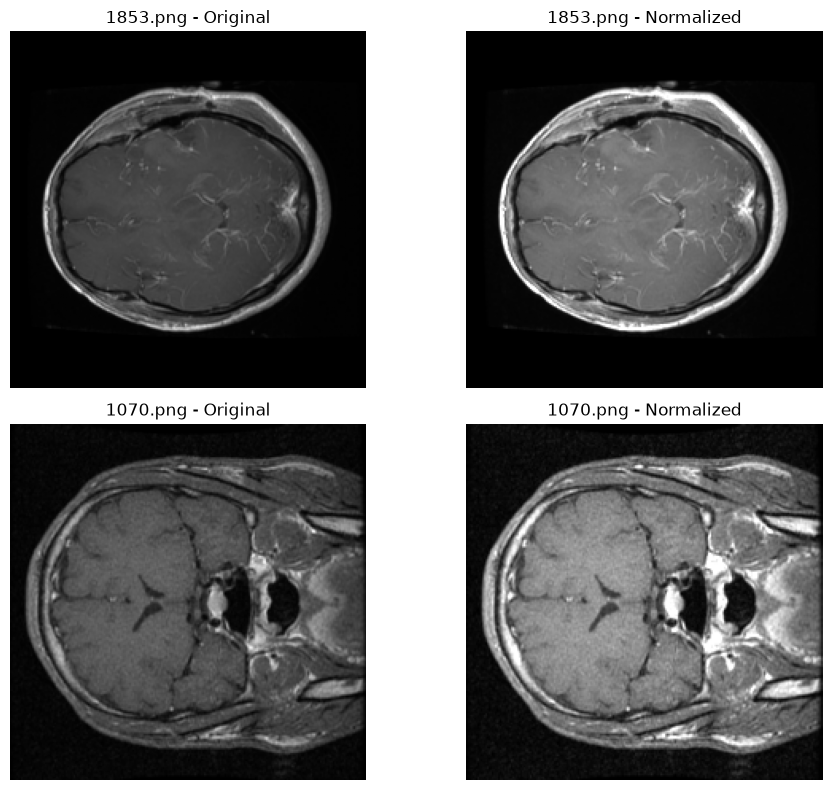

In [71]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8))

for row, path in enumerate([sample_512, sample_256]):
    with Image.open(path) as img:
        resized = img.resize((224, 224), Image.Resampling.BILINEAR)
        pixels = np.array(resized, dtype=np.float32)

        lower = np.percentile(pixels, 1)
        upper = np.percentile(pixels, 99)

        normalized = np.clip(
            (pixels - lower) / (upper - lower + 1e-8),
            0,
            1
        )

        axes[row, 0].imshow(pixels, cmap="gray")
        axes[row, 0].set_title(f"{path.name} - Original")

        axes[row, 1].imshow(normalized, cmap="gray", vmin=0, vmax=1)
        axes[row, 1].set_title(f"{path.name} - Normalized")

        print(
            f"{path.name} | Normalized range: "
            f"{normalized.min():.3f} to {normalized.max():.3f}"
        )

        for ax in axes[row]:
            ax.axis("off")

plt.tight_layout()
plt.show()

In [73]:
percentile_data = []

for class_name in ["glioma", "meningioma", "pituitary"]:
    folder = processed_dir / "train" / class_name

    for path in folder.glob("*.png"):
        with Image.open(path) as img:
            pixels = np.array(img, dtype=np.float32)

        p1 = np.percentile(pixels, 1)
        p99 = np.percentile(pixels, 99)

        percentile_data.append({
            "image": path.name,
            "class": class_name,
            "p1": p1,
            "p99": p99
        })

percentile_df = pd.DataFrame(percentile_data)

print("Training images analysed:", len(percentile_df))
print("\n99th percentile statistics:")
print(percentile_df["p99"].describe())

print("\nStatistics by class:")
print(
    percentile_df.groupby("class")[["p1", "p99"]]
    .agg(["min", "median", "max"])
)

Training images analysed: 1991

99th percentile statistics:
count    1991.000000
mean     2073.209473
std      1235.261963
min       155.000000
25%      1158.000000
50%      1953.000000
75%      2762.000000
max      6714.000000
Name: p99, dtype: float64

Statistics by class:
             p1                p99                          
            min median  max    min       median          max
class                                                       
glioma      0.0    0.0  0.0  558.0  2640.500000  6714.000000
meningioma  0.0    0.0  0.0  434.0  1808.569946  3711.000000
pituitary   0.0    0.0  0.0  155.0   651.500000  3608.570068


<Figure size 900x500 with 0 Axes>

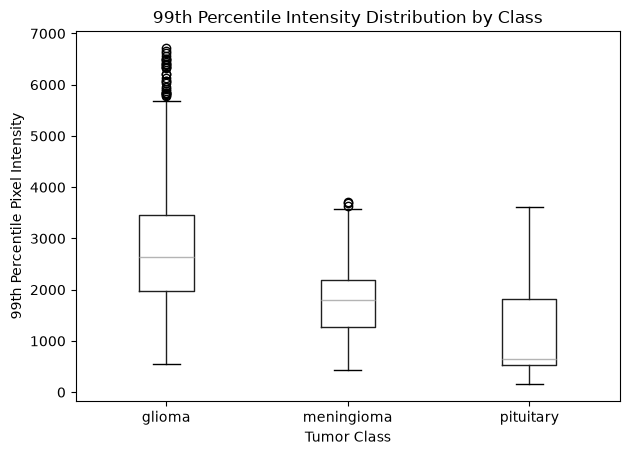

In [75]:
plt.figure(figsize=(9, 5))

percentile_df.boxplot(
    column="p99",
    by="class",
    grid=False
)

plt.title("99th Percentile Intensity Distribution by Class")
plt.suptitle("")
plt.xlabel("Tumor Class")
plt.ylabel("99th Percentile Pixel Intensity")
plt.tight_layout()
plt.show()

In [77]:
def preprocess_mri(image_path):
    with Image.open(image_path) as img:
        img = img.resize((224, 224), Image.Resampling.BILINEAR)
        pixels = np.array(img, dtype=np.float32)

    lower = np.percentile(pixels, 1)
    upper = np.percentile(pixels, 99)

    pixels = np.clip(pixels, lower, upper)
    pixels = (pixels - lower) / (upper - lower + 1e-8)

    return pixels


for path in [sample_512, sample_256]:
    normalized = preprocess_mri(path)

    print(f"File: {path.name}")
    print("Shape:", normalized.shape)
    print("Data type:", normalized.dtype)
    print("Minimum:", normalized.min())
    print("Maximum:", normalized.max())
    print("Mean:", normalized.mean())
    print("-" * 40)

File: 1853.png
Shape: (224, 224)
Data type: float32
Minimum: 0.0
Maximum: 1.0
Mean: 0.20673701
----------------------------------------
File: 1070.png
Shape: (224, 224)
Data type: float32
Minimum: 0.0
Maximum: 1.0
Mean: 0.35400125
----------------------------------------


In [79]:
def preprocess_mri_tensor(image_path):
    normalized = preprocess_mri(image_path)

    image_tensor = torch.from_numpy(normalized)
    image_tensor = image_tensor.unsqueeze(0)
    image_tensor = image_tensor.repeat(3, 1, 1)

    return image_tensor


for path in [sample_512, sample_256]:
    tensor = preprocess_mri_tensor(path)

    print(f"File: {path.name}")
    print("Tensor shape:", tensor.shape)
    print("Data type:", tensor.dtype)
    print("Minimum:", tensor.min().item())
    print("Maximum:", tensor.max().item())
    print("-" * 40)

File: 1853.png
Tensor shape: torch.Size([3, 224, 224])
Data type: torch.float32
Minimum: 0.0
Maximum: 1.0
----------------------------------------
File: 1070.png
Tensor shape: torch.Size([3, 224, 224])
Data type: torch.float32
Minimum: 0.0
Maximum: 1.0
----------------------------------------


In [91]:
print("Kernel is responsive!")
print("PyTorch:", torch.__version__)
print("Dataset class imported:", Dataset)

Kernel is responsive!
PyTorch: 2.14.1+cu130
Dataset class imported: <class 'torch.utils.data.dataset.Dataset'>


In [93]:
from torch.utils.data import Dataset

class BrainMRIDataset(Dataset):
    def __init__(self, manifest, split, processed_dir):
        self.records = manifest[
            manifest["split"] == split
        ].reset_index(drop=True)

        self.processed_dir = processed_dir

        self.class_to_idx = {
            "glioma": 0,
            "meningioma": 1,
            "pituitary": 2
        }

    def __len__(self):
        return len(self.records)

    def __getitem__(self, index):
        row = self.records.iloc[index]

        image_path = (
            self.processed_dir
            / row["split"]
            / row["label_name"]
            / f"{int(row['id'])}.png"
        )

        image = preprocess_mri_tensor(image_path)
        label = self.class_to_idx[row["label_name"]]

        return image, label

print("BrainMRIDataset class defined successfully!")

BrainMRIDataset class defined successfully!


In [95]:
train_dataset = BrainMRIDataset(
    split_manifest, "train", processed_dir
)

val_dataset = BrainMRIDataset(
    split_manifest, "validation", processed_dir
)

test_dataset = BrainMRIDataset(
    split_manifest, "test", processed_dir
)

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Testing images:", len(test_dataset))
print("Total images:", len(train_dataset) + len(val_dataset) + len(test_dataset))

Training images: 1991
Validation images: 531
Testing images: 542
Total images: 3064


In [97]:
image, label = train_dataset[0]

idx_to_class = {
    0: "glioma",
    1: "meningioma",
    2: "pituitary"
}

print("Image shape:", image.shape)
print("Image dtype:", image.dtype)
print("Label:", label)
print("Tumor class:", idx_to_class[label])
print("Minimum pixel value:", image.min().item())
print("Maximum pixel value:", image.max().item())

Image shape: torch.Size([3, 224, 224])
Image dtype: torch.float32
Label: 1
Tumor class: meningioma
Minimum pixel value: 0.0
Maximum pixel value: 1.0


In [99]:
from torch.utils.data import DataLoader

train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))

Training batches: 125
Validation batches: 34
Testing batches: 34


In [101]:
images, labels = next(iter(train_loader))

print("Batch image shape:", images.shape)
print("Batch label shape:", labels.shape)
print("Image data type:", images.dtype)
print("Label data type:", labels.dtype)

print("\nClass distribution in this batch:")

for class_id, class_name in idx_to_class.items():
    count = (labels == class_id).sum().item()
    print(f"{class_name}: {count}")

print("\nPixel range:")
print("Minimum:", images.min().item())
print("Maximum:", images.max().item())

Batch image shape: torch.Size([16, 3, 224, 224])
Batch label shape: torch.Size([16])
Image data type: torch.float32
Label data type: torch.int64

Class distribution in this batch:
glioma: 9
meningioma: 4
pituitary: 3

Pixel range:
Minimum: 0.0
Maximum: 1.0
